<a href="https://colab.research.google.com/github/boddanapurna6-oss/Deep-Learning-skills/blob/main/Deep_Learning_skill_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:

!pip install -q ultralytics pillow matplotlib


In [20]:

import torch
import time
import platform
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from ultralytics import YOLO
from google.colab import files

print("VISIONPORT - CO1")
print("-------------------------")

print("Python Version:", platform.python_version())
print("PyTorch Version:", torch.__version__)

if torch.cuda.is_available():
    DEVICE = 0
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("GPU not available. Using CPU.")


VISIONPORT - CO1
-------------------------
Python Version: 3.13.18
PyTorch Version: 2.14.1+cpu
GPU not available. Using CPU.


In [21]:

print("Loading YOLO model...")

model = YOLO("yolov8n.pt")

print("Model loaded successfully!")
print("Model: YOLOv8n")
print("Weights: yolov8n.pt")


Loading YOLO model...
Model loaded successfully!
Model: YOLOv8n
Weights: yolov8n.pt


In [22]:

print("Upload a traffic image")

uploaded = files.upload()

image_path = next(iter(uploaded))

print("Image uploaded successfully:", image_path)


Upload a traffic image


Saving yellammabanda traffic-photo-14223587.avif to yellammabanda traffic-photo-14223587 (1).avif
Image uploaded successfully: yellammabanda traffic-photo-14223587 (1).avif


In [23]:

start_time = time.perf_counter()

image = Image.open(image_path).convert("RGB")

original_width, original_height = image.size

processed_image = image.resize((640, 640))

image_array = np.array(processed_image)

image_tensor = torch.from_numpy(image_array)

preprocessing_time = (
    time.perf_counter() - start_time
) * 1000

print("IMAGE PREPROCESSING")
print("-------------------------")
print("Original Size:", image.size)
print("Processed Size:", processed_image.size)
print("Tensor Shape:", image_tensor.shape)
print("Tensor Data Type:", image_tensor.dtype)
print("Preprocessing Time:", round(preprocessing_time, 2), "ms")


IMAGE PREPROCESSING
-------------------------
Original Size: (3938, 5906)
Processed Size: (640, 640)
Tensor Shape: torch.Size([640, 640, 3])
Tensor Data Type: torch.uint8
Preprocessing Time: 960.38 ms


In [24]:

start_time = time.perf_counter()

results = model.predict(
    source=processed_image,
    device=DEVICE,
    conf=0.25,
    verbose=False
)

if torch.cuda.is_available() and DEVICE != "cpu":
    torch.cuda.synchronize()

inference_time = (
    time.perf_counter() - start_time
) * 1000

print("Object detection completed!")
print("Inference Time:", round(inference_time, 2), "ms")


Object detection completed!
Inference Time: 441.83 ms


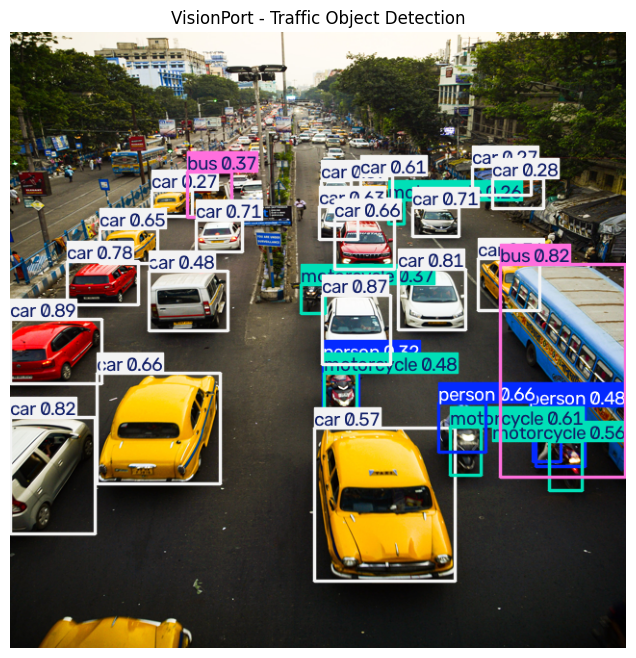

In [25]:

result = results[0]

detected_image = result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(detected_image[:, :, ::-1])
plt.title("VisionPort - Traffic Object Detection")
plt.axis("off")
plt.show()


In [26]:

print("DETECTED OBJECTS")
print("-------------------------")

for box in result.boxes:

    class_id = int(box.cls[0])

    object_name = model.names[class_id]

    confidence = float(box.conf[0])

    bounding_box = [
        round(float(value), 2)
        for value in box.xyxy[0].tolist()
    ]

    print("Object:", object_name)
    print("Confidence:", round(confidence * 100, 2), "%")
    print("Bounding Box:", bounding_box)
    print("-------------------------")

print("Total Objects Detected:", len(result.boxes))


DETECTED OBJECTS
-------------------------
Object: car
Confidence: 89.2 %
Bounding Box: [0.14, 298.2, 95.56, 365.18]
-------------------------
Object: car
Confidence: 86.77 %
Bounding Box: [324.01, 273.35, 395.38, 345.83]
-------------------------
Object: bus
Confidence: 82.37 %
Bounding Box: [509.98, 241.64, 639.59, 462.67]
-------------------------
Object: car
Confidence: 81.78 %
Bounding Box: [0.0, 400.05, 88.55, 521.36]
-------------------------
Object: car
Confidence: 80.93 %
Bounding Box: [403.49, 246.48, 473.41, 309.7]
-------------------------
Object: car
Confidence: 78.19 %
Bounding Box: [59.96, 238.28, 133.71, 283.72]
-------------------------
Object: car
Confidence: 71.26 %
Bounding Box: [418.72, 182.22, 466.32, 212.75]
-------------------------
Object: car
Confidence: 70.92 %
Bounding Box: [193.1, 195.94, 241.14, 228.7]
-------------------------
Object: car
Confidence: 66.5 %
Bounding Box: [90.14, 354.04, 218.28, 469.81]
-------------------------
Object: person
Confidence: 

In [27]:

system_layers = {
    "Input Layer": "Traffic image uploaded by user",
    "API Layer": "Receives image request",
    "Preprocessing Layer": "Image resizing and tensor preparation",
    "Model Architecture": "YOLOv8n",
    "Checkpoint Layer": "Pretrained model weights",
    "Tensor Layer": "PyTorch tensor operations",
    "Inference Layer": "Object detection execution",
    "Hardware Layer": "CPU or NVIDIA GPU",
    "Output Layer": "Object names, confidence and bounding boxes"
}

print("VISIONPORT SYSTEM ARCHITECTURE")
print("==============================")

for layer, description in system_layers.items():
    print("\n" + layer)
    print("   " + description)

print("\nCO1 IMPLEMENTATION COMPLETED")


VISIONPORT SYSTEM ARCHITECTURE

Input Layer
   Traffic image uploaded by user

API Layer
   Receives image request

Preprocessing Layer
   Image resizing and tensor preparation

Model Architecture
   YOLOv8n

Checkpoint Layer
   Pretrained model weights

Tensor Layer
   PyTorch tensor operations

Inference Layer
   Object detection execution

Hardware Layer
   CPU or NVIDIA GPU

Output Layer
   Object names, confidence and bounding boxes

CO1 IMPLEMENTATION COMPLETED
